In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA

from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
import numpy as np

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

In [ ]:
env = TwoArmedBandit(rew=1, pun=-1, pA=0.3, pB=0.1)

In [ ]:
quantiles = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
             0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
             0.65, 0.70, 0.75, 0.80, 0.85, 0.90,
             0.95]

In [ ]:
xinf = np.zeros((len(quantiles)))
dqinf = np.zeros((len(quantiles)))

In [ ]:
for i, q in enumerate(quantiles):
    mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0, 
                     choice_intensities=4, Rmin=-2, Rmax=2,
                     method='quantile', tau=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae.trajectory(X, 150)
    q_xisainf = traj[-1, :, :, :]
    q_xinf = traj[-1, 0, 0, 0]
    Qisainf = mae._Qisa(q_xisainf)
    q_dqinf = Qisainf[0, 0, 0] - Qisainf[0, 0, 1]
    xinf[i] = q_xinf
    dqinf[i] = q_dqinf

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


Text(0.5, 1.0, 'Final strategy as a function of quantile')

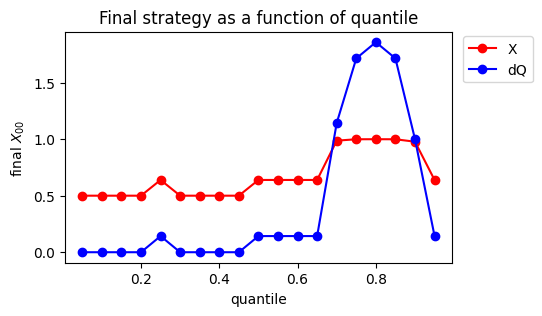

In [ ]:
# Plot
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.plot(quantiles, xinf, '-o', color='red', label="X")
ax.plot(quantiles, dqinf, '-o', color='blue', label="dQ")
ax.legend(bbox_to_anchor=(1.01, 1.01))
ax.set_xlabel("quantile")
ax.set_ylabel("final "+r'$X_{00}$')
ax.set_title("Final strategy as a function of quantile")

In [ ]:
b_pes = np.linspace(0.1, 1., 10)
b_opt = np.linspace(1., 10., 10)
b_ratios = np.zeros((19))
b_ratios[:9] = b_pes[:9]
b_ratios[9:] = b_opt

In [ ]:
def deltaQinf(p0, p1, x):
    return ((p0 * x - (1 - p0)) / (p0 * x + (1 - p0))) - ((p1 * x - (1 - p1)) / (p1 * x + (1 - p1)))

In [ ]:
def Xinf(dQ, beta):
    return 1 / (1 + np.exp(beta * (-dQ)))

In [ ]:
b_dQs = deltaQinf(0.3, 0.1, b_ratios)
b_xinf = Xinf(b_dQs, 4)

<matplotlib.legend.Legend>

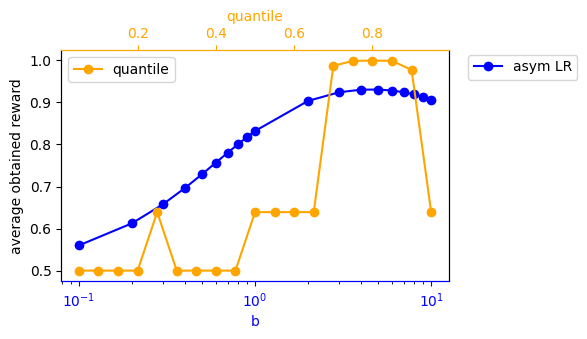

In [ ]:
# Plot
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax2 = ax.twiny()
ax.set_xscale('log')
ax2.plot(quantiles, xinf, '-o', color='orange', label="quantile")
ax.plot(b_ratios, b_xinf, '-o', color='blue', label="asym LR")
ax.legend(bbox_to_anchor=(1.01, 1.01))
ax.set_xlabel("quantile")
ax.set_ylabel("final "+r'$X_{00}$')
# ax.set_title("Final strategy as a function of quantile")
ax.set_xlabel("b", color="blue")
ax2.set_xlabel("quantile", color="orange")
ax.xaxis.label.set_color('blue')
ax.tick_params(axis='x', colors='blue')
ax2.xaxis.label.set_color('orange')
ax2.tick_params(axis='x', colors='orange')
ax.spines['bottom'].set_color('blue')
ax.spines['top'].set_color('orange')
ax2.spines['bottom'].set_color('blue')
ax2.spines['top'].set_color('orange')
ax.set_ylabel("average obtained reward")
ax2.legend()
ax.legend(bbox_to_anchor=(1.35, 1.01))